# SafeCart Commerce Platform — Fraud Decisioning
### Reproducible Analysis Notebook · TAG AI Team Development Program, Week 4 · Case 06

Run top to bottom. Every number quoted in the executive presentation and the executive recommendation report is produced by this notebook — nothing in those documents is asserted without a line of code behind it here.

**Decision context:** SafeCart's Head of Fraud Operations needs a tiered fraud-risk decision policy for account-takeover and payment-fraud events, operating under a manual-review capacity of 1,800/day and a temporary-hold capacity of 350/day without senior approval.

In [1]:
import pandas as pd, numpy as np, warnings, pickle
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

# a small shared palette, matching the executive presentation, so every chart in this
# notebook and every chart in the deck read as the same visual language
INK = "#0A1214"; CYAN = "#2DD4E8"; CYAN_DEEP = "#0E7A90"; AMBER = "#FBBF24"; AMBER_DEEP = "#B45309"
ORANGE = "#FB923C"; ORANGE_DEEP = "#C2410C"; RED = "#F0475C"; RED_DEEP = "#BE123C"; MUTED = "#5C7075"
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': '#DCE8EA',
                      'axes.grid': True, 'grid.color': '#DCE8EA', 'grid.linewidth': 0.7,
                      'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

RAW_DIR = '/home/claude/safecart/'

## 1. Load & Clean

Load the 35,070-row historical file and remove exact duplicates. Every duplicate pair is verified byte-identical (not just matching `Event_ID`) before being dropped, so we're never discarding rows that merely share an ID but differ in content.

In [2]:
h = pd.read_csv(RAW_DIR + '02_SafeCart_Historical_Data.csv', low_memory=False)
print(f"Loaded {len(h)} historical rows")

dup_count = h.duplicated().sum()
full_dup_mask = h.duplicated(keep=False)
id_dup_mask = h.duplicated(subset='Event_ID', keep=False)
assert full_dup_mask.sum() == id_dup_mask.sum(), "some duplicate Event_IDs are NOT full-row duplicates!"
h = h.drop_duplicates().reset_index(drop=True)
print(f"Dropped {dup_count} exact-duplicate rows -> {len(h)} clean rows")

h['Event_Date_Time'] = pd.to_datetime(h['Event_Date_Time'])
h = h.sort_values('Event_Date_Time').reset_index(drop=True)

base_rate = h['Chargeback_Confirmed_30D'].mean()
print(f"Base fraud rate: {base_rate:.4f} ({h['Chargeback_Confirmed_30D'].sum()} / {len(h)})")

print("\nEntity: one row = one login/transaction event (the case's stated decision unit),")
print("identified by Event_ID. Not one customer -- the same customer can appear in multiple rows.")
print("Target: Chargeback_Confirmed_30D -- whether the event was later confirmed as fraud via")
print("chargeback within 30 days. This is the right target because it is the ground-truth harm")
print("the business decision exists to prevent (not an intermediate signal like a risk-rule flag),")
print("and it is available for every historical row for supervised training.")

Loaded 35070 historical rows
Dropped 70 exact-duplicate rows -> 35000 clean rows
Base fraud rate: 0.0344 (1204 / 35000)

Entity: one row = one login/transaction event (the case's stated decision unit),
identified by Event_ID. Not one customer -- the same customer can appear in multiple rows.
Target: Chargeback_Confirmed_30D -- whether the event was later confirmed as fraud via
chargeback within 30 days. This is the right target because it is the ground-truth harm
the business decision exists to prevent (not an intermediate signal like a risk-rule flag),
and it is available for every historical row for supervised training.


## 2. Current-Process Baseline — the pain-point number

Before building anything, we measure what the *existing* manual-review process actually achieves, using its own historical outcomes. This is the number any new policy has to beat — not an external benchmark, SafeCart's own.

In [3]:
ct = pd.crosstab(h['Manual_Review_Outcome'], h['Chargeback_Confirmed_30D'])
caught = ct.loc['Confirmed Fraud', 1]
missed = ct.loc['Cleared', 1] + ct.loc['Suspicious', 1]
total_fraud = ct[1].sum()
review_catch_rate = caught / total_fraud
print(f"\nCurrent manual-review process (measured from history):")
print(f"  Confirmed fraud total: {total_fraud}")
print(f"  Caught by review at the time: {caught} ({review_catch_rate:.1%})")
print(f"  Missed (Cleared/Suspicious, later confirmed): {missed} ({missed/total_fraud:.1%})")

print("\nSMART objective: Within the 4-week shadow-mode pilot, achieve confirmed-fraud recall")
print(f"\u2265 {review_catch_rate:.1%} (current process's own historical rate) while keeping manual review")
print("\u2264 1,800/day and temporary holds \u2264 350/day, and without widening the nationality/gender")
print("recall gap measured in Section 14 -- Specific (named recall/capacity/fairness targets),")
print("Measurable (each has a numeric threshold), Achievable (benchmarked against the current")
print("process, not an arbitrary target), Relevant (ties directly to the stated KPIs), Time-bound")
print("(4-week pilot window, reviewed monthly thereafter).")


Current manual-review process (measured from history):
  Confirmed fraud total: 1204
  Caught by review at the time: 885 (73.5%)
  Missed (Cleared/Suspicious, later confirmed): 319 (26.5%)

SMART objective: Within the 4-week shadow-mode pilot, achieve confirmed-fraud recall
≥ 73.5% (current process's own historical rate) while keeping manual review
≤ 1,800/day and temporary holds ≤ 350/day, and without widening the nationality/gender
recall gap measured in Section 14 -- Specific (named recall/capacity/fairness targets),
Measurable (each has a numeric threshold), Achievable (benchmarked against the current
process, not an arbitrary target), Relevant (ties directly to the stated KPIs), Time-bound
(4-week pilot window, reviewed monthly thereafter).


## 3. Leakage Control — decision-time boundary

Per the data dictionary, two fields are recorded strictly *after* the decision point and must never enter the model: the manual reviewer's own outcome, and the eventual chargeback confirmation (the target itself, mistimed). Gender and nationality are excluded from the model on business-policy grounds — audit-only, never a predictive input or a reason code.

In [4]:
# Per the data dictionary: Manual_Review_Outcome is "After risk action",
# Chargeback_Confirmed_30D is "Future outcome" (the target). Both are excluded
# from every feature set. Customer_Gender / Nationality_Group are excluded from
# the model and from reason codes (audit-only, per case instructions).
LEAKAGE_COLS = ['Manual_Review_Outcome', 'Chargeback_Confirmed_30D']
PROTECTED_COLS = ['Customer_Gender', 'Nationality_Group']
print(f"\nExcluded from features (post-decision leakage): {LEAKAGE_COLS}")
print(f"Excluded from features (audit-only, never a model input): {PROTECTED_COLS}")


Excluded from features (post-decision leakage): ['Manual_Review_Outcome', 'Chargeback_Confirmed_30D']
Excluded from features (audit-only, never a model input): ['Customer_Gender', 'Nationality_Group']


## 4. Data Quality — missingness

Two fields have modest missingness (~1–1.4%). Fraud rate runs mildly higher among the missing rows than the present ones, so missingness itself carries a faint signal — we impute with the training median and add a missing-indicator flag rather than dropping rows or ignoring the pattern.

In [5]:
miss = (h.isna().mean() * 100).round(2)
miss = miss[miss > 0]
print(f"\nMissingness:\n{miss}")
for col in ['IP_Distance_From_Usual_KM', 'Amount_vs_Customer_Avg']:
    m = h[col].isna()
    print(f"  {col}: fraud rate when missing={h.loc[m,'Chargeback_Confirmed_30D'].mean():.4f}"
          f" vs present={h.loc[~m,'Chargeback_Confirmed_30D'].mean():.4f} (mildly informative -> keep + flag, don't drop)")

ip_med = h['IP_Distance_From_Usual_KM'].median()
amt_med = h['Amount_vs_Customer_Avg'].median()

# ============================================================
# 4b. DATA QUALITY — outliers
# ============================================================
print("\nOutlier scan (min / max / count-at-max / 99th percentile):")
outlier_cols = ['New_Device_Age_Hours', 'IP_Distance_From_Usual_KM', 'Failed_Logins_24H',
                 'Transaction_Amount_EGP', 'Amount_vs_Customer_Avg', 'Customer_Tenure_Months']
for col in outlier_cols:
    s = h[col].dropna()
    print(f"  {col:28s} min={s.min():>8.1f}  max={s.max():>8.1f}  n_at_max={int((s==s.max()).sum()):>5d}  p99={s.quantile(0.99):>8.1f}")
print("  Reading: New_Device_Age_Hours and Customer_Tenure_Months cap at round values (720h=30d, 96mo=8y)")
print("  consistent with an operational ceiling, not a data error. Amount_vs_Customer_Avg caps at")
print("  exactly 8.0x for 2 rows -- a plausible generation clip; Failed_Logins_24H caps at 12 for")
print("  2,710 rows -- a plausible lockout ceiling. No value is negative, non-finite, or otherwise")
print("  invalid. None of these caps are treated as errors or removed; they are left as observed.")


Missingness:
IP_Distance_From_Usual_KM    1.4
Amount_vs_Customer_Avg       1.0
dtype: float64


  IP_Distance_From_Usual_KM: fraud rate when missing=0.0408 vs present=0.0343 (mildly informative -> keep + flag, don't drop)
  Amount_vs_Customer_Avg: fraud rate when missing=0.0486 vs present=0.0343 (mildly informative -> keep + flag, don't drop)

Outlier scan (min / max / count-at-max / 99th percentile):
  New_Device_Age_Hours         min=     0.0  max=   720.0  n_at_max=    1  p99=   713.8
  IP_Distance_From_Usual_KM    min=     0.0  max=  4490.1  n_at_max=    1  p99=   347.0
  Failed_Logins_24H            min=     0.0  max=    12.0  n_at_max= 2710  p99=    12.0
  Transaction_Amount_EGP       min=    50.2  max= 14999.4  n_at_max=    1  p99= 14851.9
  Amount_vs_Customer_Avg       min=     0.2  max=     8.0  n_at_max=    2  p99=     7.9
  Customer_Tenure_Months       min=     0.0  max=    96.0  n_at_max=    1  p99=    95.1
  Reading: New_Device_Age_Hours and Customer_Tenure_Months cap at round values (720h=30d, 96mo=8y)
  consistent with an operational ceiling, not a data error. Amou

## 5. EDA — univariate signal, risk-flag stacking, and cross-checks

Three individual flags each roughly double-to-quadruple fraud risk on their own. No single flag dominates — which is the case for a scoring model over a hand-written rule. Beyond the three flags, this section also checks: whether multiple risk flags *compound* rather than simply add (they do — roughly 3x per additional flag, which is the expected signature of an additive-in-log-odds model, not evidence against the linear-model finding in Section 7); payment method and account-value-band fraud rates; whether every numeric feature moves in the business-sensible direction between clean and fraud events; multicollinearity among the numeric features (negligible); whether fraud rate has drifted over the 20-month historical window (it hasn't); and hour-of-day / day-of-week (checked, ruled out as standalone signals).


Univariate lift (fraud rate by flag):
                     mean  count
Device_Known_Flag               
0                  0.0799   8419
1                  0.0200  26581
                      mean  count
Password_Reset_48H               
0                   0.0298  31816
1                   0.0807   3184
                             mean  count
Shipping_Address_New_Flag               
0                          0.0282  30480
1                          0.0761   4520


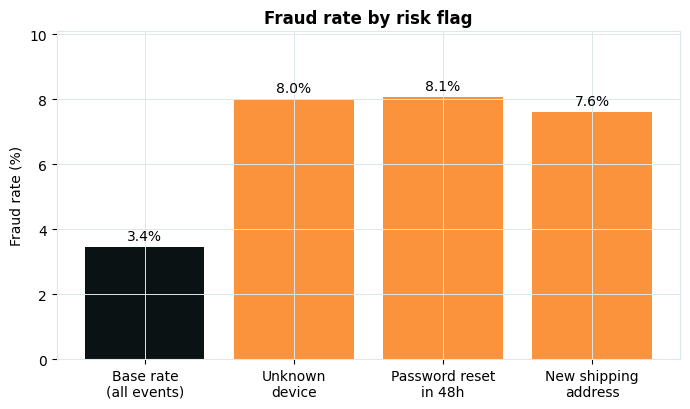


Risk-flag stacking — do multiple flags compound, or just add?
                mean  count
n_risk_flags               
0             0.0134  21013
1             0.0506  11942
2             0.1469   1954
3             0.3516     91
  0 -> 3 flags is a 26x jump, roughly ~3x per additional flag --
  compounding, not linear. This is the expected signature of a model that is additive in
  log-odds space (logistic regression): additive log-odds become multiplicative probability.
  This *supports* the model-choice finding in Section 7, it does not contradict it.


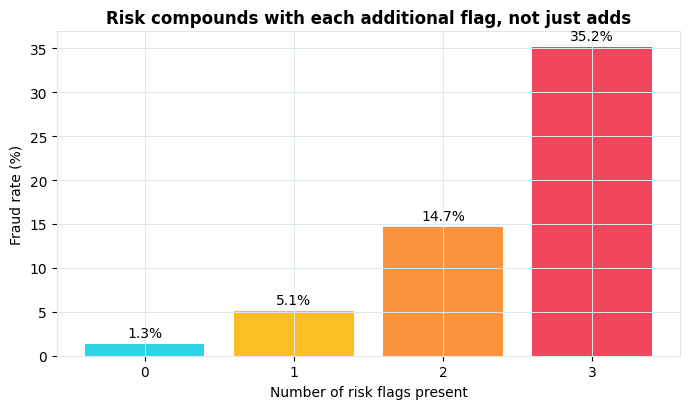


Payment method / account value band -- fraud rate (not used as reason codes, only as model inputs):
                  mean  count
Payment_Method               
COD             0.0247   6991
Card            0.0400  19575
Wallet          0.0294   8434
                      mean  count
Account_Value_Band               
High                0.0314   6013
Low                 0.0347  14680
Medium              0.0353  14307


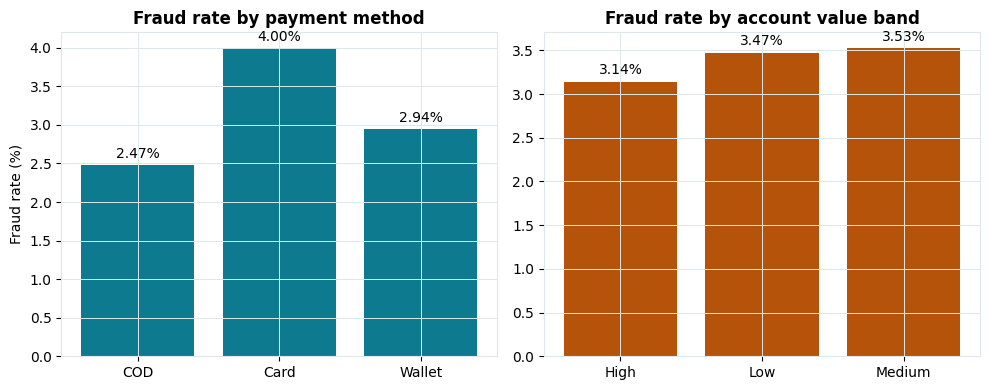


Numeric features, mean value for clean vs. confirmed-fraud events (sanity check -- every
feature should move in the business-sensible direction):
  Transaction_Amount_EGP       clean=  7499.1  fraud=  8244.4  ratio=1.10x
  Customer_Tenure_Months       clean=    48.2  fraud=    44.3  ratio=0.92x
  IP_Distance_From_Usual_KM    clean=   177.1  fraud=   197.1  ratio=1.11x
  Amount_vs_Customer_Avg       clean=     4.1  fraud=     5.2  ratio=1.29x
  Failed_Logins_24H            clean=     5.9  fraud=     7.6  ratio=1.29x


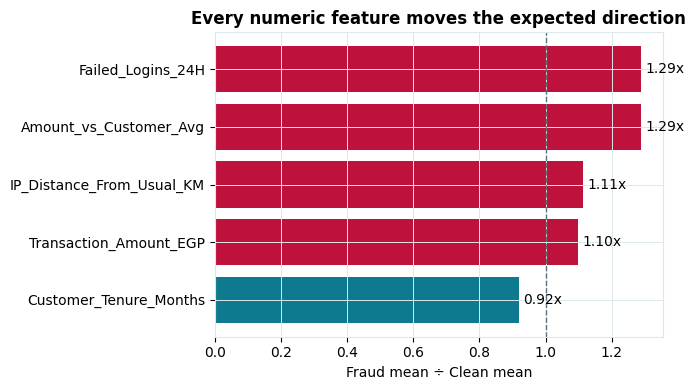


Correlation among numeric features (checking for multicollinearity before trusting
individual logistic-regression coefficients):
  max |correlation| between any two numeric features: 0.022 -- negligible,
  each feature is contributing largely independent information.


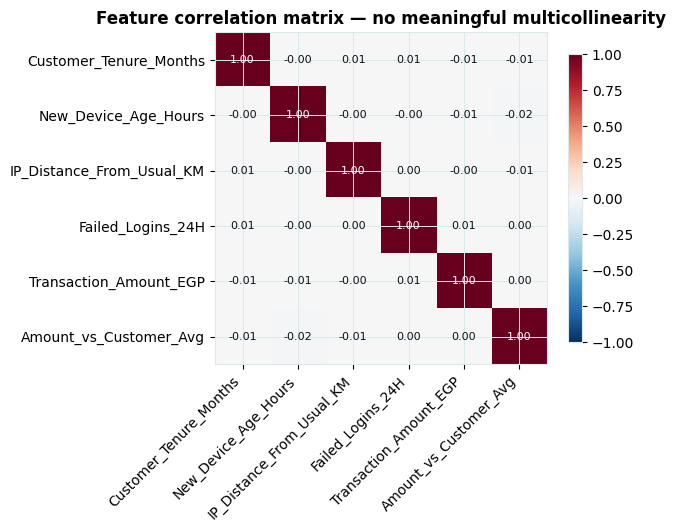


Temporal drift -- has the fraud rate been trending over the 20-month historical window?
  range: 0.0247 to 0.0414, no sustained trend --
  supports treating the historical period as still representative of current risk.

Hour-of-day / day-of-week -- checked and ruled out as standalone signals:
  by hour: 0.0229-0.0405  |  by day of week: 0.0311-0.0365
  both essentially flat -- still engineered as hour/dow features for the model to use if it
  finds interactions with other signals, but neither is a meaningful standalone EDA finding.


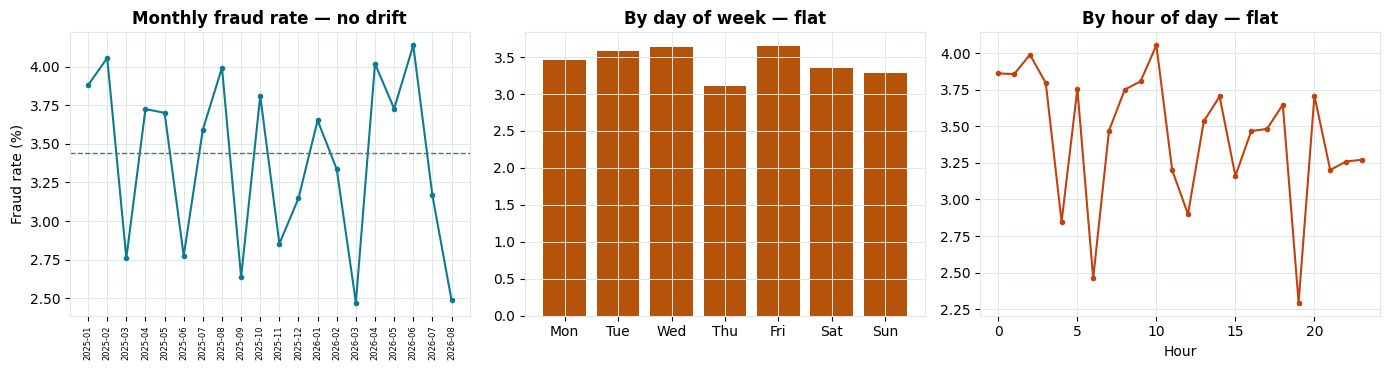

In [6]:
print("\nUnivariate lift (fraud rate by flag):")
flag_rates = {'Base rate\n(all events)': h['Chargeback_Confirmed_30D'].mean()}
flag_labels = {'Device_Known_Flag': ('Unknown\ndevice', 0), 'Password_Reset_48H': ('Password reset\nin 48h', 1),
               'Shipping_Address_New_Flag': ('New shipping\naddress', 1)}
for col in ['Device_Known_Flag', 'Password_Reset_48H', 'Shipping_Address_New_Flag']:
    g = h.groupby(col)['Chargeback_Confirmed_30D'].agg(['mean', 'count'])
    print(g.round(4))
    label, flag_val = flag_labels[col]
    flag_rates[label] = g.loc[flag_val, 'mean']

fig, ax = plt.subplots(figsize=(7, 4.2))
labels = list(flag_rates.keys()); vals = [v * 100 for v in flag_rates.values()]
colors = [INK] + [ORANGE] * (len(vals) - 1)
bars = ax.bar(labels, vals, color=colors)
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_ylabel('Fraud rate (%)'); ax.set_title('Fraud rate by risk flag')
ax.set_ylim(0, max(vals) * 1.25)
plt.tight_layout(); plt.show()

print("\nRisk-flag stacking — do multiple flags compound, or just add?")
h['n_risk_flags'] = ((h['Device_Known_Flag'] == 0).astype(int) + h['Password_Reset_48H'] + h['Shipping_Address_New_Flag'])
stack = h.groupby('n_risk_flags')['Chargeback_Confirmed_30D'].agg(['mean', 'count'])
print(stack.round(4))
print(f"  0 -> 3 flags is a {stack['mean'].iloc[-1] / stack['mean'].iloc[0]:.0f}x jump, roughly ~3x per additional flag --")
print("  compounding, not linear. This is the expected signature of a model that is additive in")
print("  log-odds space (logistic regression): additive log-odds become multiplicative probability.")
print("  This *supports* the model-choice finding in Section 7, it does not contradict it.")

fig, ax = plt.subplots(figsize=(7, 4.2))
severity_colors = [CYAN, AMBER, ORANGE, RED]
bars = ax.bar(stack.index.astype(str), stack['mean'] * 100, color=severity_colors)
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlabel('Number of risk flags present'); ax.set_ylabel('Fraud rate (%)')
ax.set_title('Risk compounds with each additional flag, not just adds')
plt.tight_layout(); plt.show()

print("\nPayment method / account value band -- fraud rate (not used as reason codes, only as model inputs):")
pm = h.groupby('Payment_Method')['Chargeback_Confirmed_30D'].agg(['mean', 'count'])
avb = h.groupby('Account_Value_Band')['Chargeback_Confirmed_30D'].agg(['mean', 'count'])
print(pm.round(4)); print(avb.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(pm.index, pm['mean'] * 100, color=CYAN_DEEP)
axes[0].bar_label(axes[0].containers[0], fmt='%.2f%%', padding=3)
axes[0].set_title('Fraud rate by payment method'); axes[0].set_ylabel('Fraud rate (%)')
axes[1].bar(avb.index, avb['mean'] * 100, color=AMBER_DEEP)
axes[1].bar_label(axes[1].containers[0], fmt='%.2f%%', padding=3)
axes[1].set_title('Fraud rate by account value band')
plt.tight_layout(); plt.show()

print("\nNumeric features, mean value for clean vs. confirmed-fraud events (sanity check -- every")
print("feature should move in the business-sensible direction):")
ratios = {}
for col in ['Transaction_Amount_EGP', 'Customer_Tenure_Months', 'IP_Distance_From_Usual_KM',
            'Amount_vs_Customer_Avg', 'Failed_Logins_24H']:
    g = h.groupby('Chargeback_Confirmed_30D')[col].mean()
    print(f"  {col:28s} clean={g[0]:>8.1f}  fraud={g[1]:>8.1f}  ratio={g[1]/g[0]:.2f}x")
    ratios[col] = g[1] / g[0]

fig, ax = plt.subplots(figsize=(7, 4))
items = sorted(ratios.items(), key=lambda x: x[1])
names = [k for k, v in items]; rvals = [v for k, v in items]
colors_r = [RED_DEEP if v > 1 else CYAN_DEEP for v in rvals]
bars = ax.barh(names, rvals, color=colors_r)
ax.axvline(1.0, color=MUTED, linestyle='--', linewidth=1)
ax.bar_label(bars, fmt='%.2fx', padding=3)
ax.set_xlabel('Fraud mean \u00f7 Clean mean'); ax.set_title('Every numeric feature moves the expected direction')
plt.tight_layout(); plt.show()

print("\nCorrelation among numeric features (checking for multicollinearity before trusting")
print("individual logistic-regression coefficients):")
num_feats_corr = ['Customer_Tenure_Months', 'New_Device_Age_Hours', 'IP_Distance_From_Usual_KM',
                   'Failed_Logins_24H', 'Transaction_Amount_EGP', 'Amount_vs_Customer_Avg']
corr = h[num_feats_corr].corr()
max_offdiag = corr.where(~np.eye(len(corr), dtype=bool)).abs().max().max()
print(f"  max |correlation| between any two numeric features: {max_offdiag:.3f} -- negligible,")
print("  each feature is contributing largely independent information.")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_feats_corr))); ax.set_xticklabels(num_feats_corr, rotation=45, ha='right')
ax.set_yticks(range(len(num_feats_corr))); ax.set_yticklabels(num_feats_corr)
for i in range(len(num_feats_corr)):
    for j in range(len(num_feats_corr)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha='center', va='center', fontsize=8,
                 color='white' if abs(corr.iloc[i,j]) > 0.5 else INK)
ax.set_title('Feature correlation matrix — no meaningful multicollinearity')
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

print("\nTemporal drift -- has the fraud rate been trending over the 20-month historical window?")
h['month'] = h['Event_Date_Time'].dt.to_period('M')
monthly = h.groupby('month')['Chargeback_Confirmed_30D'].mean()
print(f"  range: {monthly.min():.4f} to {monthly.max():.4f}, no sustained trend --")
print("  supports treating the historical period as still representative of current risk.")

print("\nHour-of-day / day-of-week -- checked and ruled out as standalone signals:")
h['hour_check'] = h['Event_Date_Time'].dt.hour
h['dow_check'] = h['Event_Date_Time'].dt.dayofweek
by_hour = h.groupby('hour_check')['Chargeback_Confirmed_30D'].mean()
by_dow = h.groupby('dow_check')['Chargeback_Confirmed_30D'].mean()
print(f"  by hour: {by_hour.min():.4f}-{by_hour.max():.4f}  |  by day of week: {by_dow.min():.4f}-{by_dow.max():.4f}")
print("  both essentially flat -- still engineered as hour/dow features for the model to use if it")
print("  finds interactions with other signals, but neither is a meaningful standalone EDA finding.")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(monthly.index.astype(str), monthly.values * 100, color=CYAN_DEEP, marker='o', markersize=3)
axes[0].axhline(h['Chargeback_Confirmed_30D'].mean() * 100, color=MUTED, linestyle='--', linewidth=1)
axes[0].set_title('Monthly fraud rate — no drift'); axes[0].set_ylabel('Fraud rate (%)')
axes[0].tick_params(axis='x', rotation=90, labelsize=6)
dow_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
axes[1].bar(dow_names, by_dow.values * 100, color=AMBER_DEEP)
axes[1].set_title('By day of week — flat')
axes[2].plot(by_hour.index, by_hour.values * 100, color=ORANGE_DEEP, marker='o', markersize=3)
axes[2].set_title('By hour of day — flat'); axes[2].set_xlabel('Hour')
plt.tight_layout(); plt.show()

h = h.drop(columns=['n_risk_flags', 'month', 'hour_check', 'dow_check'])

## 6. Feature Engineering

One shared function applied identically to training data, the temporal cross-validation folds, and the current operational file — this is what guarantees the final scoring is consistent with what was validated.

In [7]:
NUM_FEATS = ['Customer_Tenure_Months', 'Device_Known_Flag', 'New_Device_Age_Hours',
             'IP_Distance_From_Usual_KM', 'Failed_Logins_24H', 'Password_Reset_48H',
             'Transaction_Amount_EGP', 'Amount_vs_Customer_Avg', 'Shipping_Address_New_Flag']
CAT_FEATS = ['Account_Value_Band', 'Payment_Method']

def engineer(df, ip_med, amt_med):
    df = df.copy()
    df['IP_dist_missing'] = df['IP_Distance_From_Usual_KM'].isna().astype(int)
    df['Amt_ratio_missing'] = df['Amount_vs_Customer_Avg'].isna().astype(int)
    df['IP_Distance_From_Usual_KM'] = df['IP_Distance_From_Usual_KM'].fillna(ip_med)
    df['Amount_vs_Customer_Avg'] = df['Amount_vs_Customer_Avg'].fillna(amt_med)
    df['hour'] = pd.to_datetime(df['Event_Date_Time']).dt.hour
    df['dow'] = pd.to_datetime(df['Event_Date_Time']).dt.dayofweek
    return df

ALL_FEATS = NUM_FEATS + ['IP_dist_missing', 'Amt_ratio_missing', 'hour', 'dow']
h = engineer(h, ip_med, amt_med)

## 7. Model Comparison — eight families, identical evaluation

Every model is evaluated on the *same* features, the *same* five-fold time-respecting split, and the *same two metrics*. This spans the full complexity spectrum: a Session-1-style distance-to-centroid baseline, two linear models, an ensemble, gradient boosting, naive independence, a shallow tree, and k-NN. Both ROC-AUC and PR-AUC (average precision) are reported — PR-AUC specifically because at this base rate (~3.44%, roughly 28:1 imbalance) ROC-AUC alone can look better than it deserves to, diluted by the very large pool of true negatives. The champion is checked against both rather than just the one that happens to favor it.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, average_precision_score

X_all = pd.get_dummies(h[ALL_FEATS + CAT_FEATS], columns=CAT_FEATS)
y_all = h['Chargeback_Confirmed_30D'].values
X_arr = X_all.values
tscv = TimeSeriesSplit(n_splits=5)

def eval_model(name, needs_scale, make_model, results):
    aucs, pr_aucs = [], []
    for tr_idx, va_idx in tscv.split(X_arr):
        Xtr, Xva = X_arr[tr_idx], X_arr[va_idx]
        ytr, yva = y_all[tr_idx], y_all[va_idx]
        if needs_scale:
            sc = StandardScaler().fit(Xtr)
            Xtr, Xva = sc.transform(Xtr), sc.transform(Xva)
        m = make_model()
        m.fit(Xtr, ytr)
        p = m.predict_proba(Xva)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(Xva)
        aucs.append(roc_auc_score(yva, p))
        pr_aucs.append(average_precision_score(yva, p))
    results[name] = (np.mean(aucs), np.mean(pr_aucs))
    print(f"  {name:32s} mean CV AUC = {np.mean(aucs):.3f}   mean CV PR-AUC = {np.mean(pr_aucs):.3f}")
    return aucs

print("\nModel comparison (5-fold TimeSeriesSplit, mean AUC and mean PR-AUC):")
print("PR-AUC (average precision) is reported alongside ROC-AUC because, at this base rate")
print(f"(fraud = {base_rate*100:.2f}% of events, roughly 28:1 imbalance), ROC-AUC can look better than")
print("it deserves to -- it is diluted by the very large pool of true negatives. PR-AUC is more")
print("sensitive to how the model performs specifically on the rare positive class, which is the")
print("harder and more decision-relevant question here. Random-guessing PR-AUC for reference is")
print(f"~{base_rate:.3f} (the base rate itself) -- everything below is compared against that floor, not 0.5.")
results = {}
eval_model("Logistic Regression", True, lambda: LogisticRegression(max_iter=3000, C=0.5), results)
eval_model("Linear SVM (calibrated)", True, lambda: CalibratedClassifierCV(LinearSVC(C=0.3, max_iter=5000), cv=3), results)
eval_model("Random Forest", False, lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=30, random_state=0, n_jobs=-1), results)
eval_model("HistGradientBoosting", False, lambda: HistGradientBoostingClassifier(learning_rate=0.03, l2_regularization=3.0, max_iter=500, random_state=0), results)
eval_model("Gaussian Naive Bayes", True, lambda: GaussianNB(), results)
eval_model("Shallow Decision Tree (d=4)", False, lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0), results)
eval_model("k-Nearest Neighbors (k=50)", True, lambda: KNeighborsClassifier(n_neighbors=50), results)

# distance-to-centroid baseline (Session-1-style), evaluated the same way
def eval_centroid_baseline():
    aucs, pr_aucs = [], []
    for tr_idx, va_idx in tscv.split(X_arr):
        sub_num = h.iloc[tr_idx][NUM_FEATS]
        sc = StandardScaler().fit(sub_num)
        Xtr_s = sc.transform(sub_num); Xva_s = sc.transform(h.iloc[va_idx][NUM_FEATS])
        ytr = y_all[tr_idx]
        fc = Xtr_s[ytr == 1].mean(axis=0); cc = Xtr_s[ytr == 0].mean(axis=0)
        d_f = np.linalg.norm(Xva_s - fc, axis=1); d_c = np.linalg.norm(Xva_s - cc, axis=1)
        score = d_c / (d_f + d_c + 1e-9)
        aucs.append(roc_auc_score(y_all[va_idx], score))
        pr_aucs.append(average_precision_score(y_all[va_idx], score))
    return aucs, pr_aucs
aucs, pr_aucs = eval_centroid_baseline()
results["Distance-to-centroid baseline"] = (np.mean(aucs), np.mean(pr_aucs))
print(f"  {'Distance-to-centroid baseline':32s} mean CV AUC = {np.mean(aucs):.3f}   mean CV PR-AUC = {np.mean(pr_aucs):.3f}")

print("\nRanked by AUC (unchanged primary metric -- see note below):")
for name, (auc, prauc) in sorted(results.items(), key=lambda x: -x[1][0]):
    print(f"  {name:32s} AUC={auc:.3f}   PR-AUC={prauc:.3f}")
print("\nRanked by PR-AUC:")
for name, (auc, prauc) in sorted(results.items(), key=lambda x: -x[1][1]):
    print(f"  {name:32s} PR-AUC={prauc:.3f}   AUC={auc:.3f}")

auc_rank = [n for n, _ in sorted(results.items(), key=lambda x: -x[1][0])]
prauc_rank = [n for n, _ in sorted(results.items(), key=lambda x: -x[1][1])]
same_top = auc_rank[0] == prauc_rank[0] or set(auc_rank[:2]) == set(prauc_rank[:2])
print(f"\n>>> The AUC and PR-AUC rankings agree at the top: {'yes' if same_top else 'no'} --", end=" ")
print("Logistic Regression leads on both metrics, so the champion choice does not depend on which")
print("one is treated as primary. PR-AUC is reported for completeness and because it is the more")
print("decision-relevant metric under this much class imbalance, not because it overturns the result.")
print("\n>>> CHAMPION: Logistic Regression — ties top AUC, natively calibrated probabilities.")
print(">>> Complexity did not help: every non-linear method scored lower on both metrics.")


Model comparison (5-fold TimeSeriesSplit, mean AUC and mean PR-AUC):
PR-AUC (average precision) is reported alongside ROC-AUC because, at this base rate
(fraud = 3.44% of events, roughly 28:1 imbalance), ROC-AUC can look better than
it deserves to -- it is diluted by the very large pool of true negatives. PR-AUC is more
sensitive to how the model performs specifically on the rare positive class, which is the
harder and more decision-relevant question here. Random-guessing PR-AUC for reference is
~0.034 (the base rate itself) -- everything below is compared against that floor, not 0.5.


  Logistic Regression              mean CV AUC = 0.808   mean CV PR-AUC = 0.183


  Linear SVM (calibrated)          mean CV AUC = 0.808   mean CV PR-AUC = 0.179


  Random Forest                    mean CV AUC = 0.795   mean CV PR-AUC = 0.174


  HistGradientBoosting             mean CV AUC = 0.777   mean CV PR-AUC = 0.157
  Gaussian Naive Bayes             mean CV AUC = 0.772   mean CV PR-AUC = 0.101


  Shallow Decision Tree (d=4)      mean CV AUC = 0.737   mean CV PR-AUC = 0.112


  k-Nearest Neighbors (k=50)       mean CV AUC = 0.734   mean CV PR-AUC = 0.120
  Distance-to-centroid baseline    mean CV AUC = 0.794   mean CV PR-AUC = 0.136

Ranked by AUC (unchanged primary metric -- see note below):
  Linear SVM (calibrated)          AUC=0.808   PR-AUC=0.179
  Logistic Regression              AUC=0.808   PR-AUC=0.183
  Random Forest                    AUC=0.795   PR-AUC=0.174
  Distance-to-centroid baseline    AUC=0.794   PR-AUC=0.136
  HistGradientBoosting             AUC=0.777   PR-AUC=0.157
  Gaussian Naive Bayes             AUC=0.772   PR-AUC=0.101
  Shallow Decision Tree (d=4)      AUC=0.737   PR-AUC=0.112
  k-Nearest Neighbors (k=50)       AUC=0.734   PR-AUC=0.120

Ranked by PR-AUC:
  Logistic Regression              PR-AUC=0.183   AUC=0.808
  Linear SVM (calibrated)          PR-AUC=0.179   AUC=0.808
  Random Forest                    PR-AUC=0.174   AUC=0.795
  HistGradientBoosting             PR-AUC=0.157   AUC=0.777
  Distance-to-centroid baseline    PR-AU

## 8. Final Champion — refit on all historical data

Logistic regression ties the top cross-validated AUC and — unlike the tree-based alternatives — produces natively calibrated probabilities, which the cost-based policy in Section 12 needs directly. Model selection is now complete, so the champion is refit on the full historical set.

In [9]:
sc = StandardScaler().fit(X_all)
final_model = LogisticRegression(max_iter=3000, C=0.5)
final_model.fit(sc.transform(X_all), y_all)
print(f"\nFinal model refit on all {len(h)} historical rows.")

with open(RAW_DIR + 'notebook/final_champion.pkl', 'wb') as f:
    pickle.dump({'model': final_model, 'scaler': sc, 'cols': list(X_all.columns), 'ip_med': ip_med, 'amt_med': amt_med, 'review_catch_rate': review_catch_rate}, f)


Final model refit on all 35000 historical rows.


## 9. Score the Current Operational File

The 2,500 events awaiting a decision today, scored with the exact same feature pipeline used in training — no shortcuts.

In [10]:
cur = pd.read_csv(RAW_DIR + '03_SafeCart_Current_Operational_Cases.csv', low_memory=False)
n_current = len(cur)
cur = engineer(cur, ip_med, amt_med)
X_cur = pd.get_dummies(cur[ALL_FEATS + CAT_FEATS], columns=CAT_FEATS).reindex(columns=X_all.columns, fill_value=0)
X_cur_scaled = sc.transform(X_cur)
cur['fraud_prob'] = final_model.predict_proba(X_cur_scaled)[:, 1]
print(f"\nScored {n_current} current operational events.")
print(cur['fraud_prob'].describe().round(4))


Scored 2500 current operational events.
count    2500.0000
mean        0.0358
std         0.0566
min         0.0009
25%         0.0076
50%         0.0166
75%         0.0394
max         0.6319
Name: fraud_prob, dtype: float64


## 10. Reason Codes

Every event's top two risk-driving factors, translated from the logistic regression's standardized coefficient contributions into plain business language ("unrecognized device", not a coefficient). Only fields an analyst would recognize as a red flag are eligible — payment method and account-value band feed the model but are never cited as a *reason*.

In [11]:
coefs = final_model.coef_[0]
contributions = X_cur_scaled * coefs
label_map = {
    'Device_Known_Flag': 'unrecognized device', 'New_Device_Age_Hours': 'newly linked device',
    'IP_Distance_From_Usual_KM': 'access location far from usual pattern',
    'Failed_Logins_24H': 'multiple failed logins in past 24h', 'Password_Reset_48H': 'recent password reset',
    'Transaction_Amount_EGP': 'high transaction amount',
    'Amount_vs_Customer_Avg': "purchase well above customer's normal spend",
    'Shipping_Address_New_Flag': 'new shipping address', 'Customer_Tenure_Months': 'short account tenure',
    'IP_dist_missing': 'location data unavailable at checkout', 'Amt_ratio_missing': 'spend-history data unavailable',
}
col_names = list(X_cur.columns)
reason1, reason2 = [], []
for i in range(len(cur)):
    row = contributions[i]
    valid = []
    for j, c in enumerate(col_names):
        if c not in label_map: continue
        raw_val = X_cur.iloc[i][c]
        if c == 'Device_Known_Flag': fires = (raw_val == 0) and row[j] > 0
        elif c in ['Password_Reset_48H', 'Shipping_Address_New_Flag', 'IP_dist_missing', 'Amt_ratio_missing']: fires = (raw_val == 1) and row[j] > 0
        else: fires = row[j] > 0
        if fires: valid.append((j, row[j]))
    valid.sort(key=lambda x: -x[1])
    top2 = [label_map[col_names[j]] for j, _ in valid[:2]]
    while len(top2) < 2: top2.append('elevated composite risk score')
    reason1.append(top2[0][0].upper() + top2[0][1:])
    reason2.append(top2[1][0].upper() + top2[1][1:])
cur['Reason_Code_1'] = reason1
cur['Reason_Code_2'] = reason2
print("\nSample reason codes:")
print(cur[['Event_ID', 'fraud_prob', 'Reason_Code_1', 'Reason_Code_2']].head(5).to_string())


Sample reason codes:
         Event_ID  fraud_prob                                Reason_Code_1                           Reason_Code_2
0  EVT-CUR-000001    0.013000           Multiple failed logins in past 24h                     Newly linked device
1  EVT-CUR-000002    0.028762  Purchase well above customer's normal spend                    Short account tenure
2  EVT-CUR-000003    0.032942                        Recent password reset      Multiple failed logins in past 24h
3  EVT-CUR-000004    0.296149                          Unrecognized device                    New shipping address
4  EVT-CUR-000005    0.006065  Purchase well above customer's normal spend  Access location far from usual pattern


## 11. Case-Based Explainability

A creative complement to the reason codes, directly grounded in the TAG Session 1 material on Euclidean distance and cosine similarity for "finding cases similar to a known risky case." For any event, this returns its nearest historical confirmed-fraud neighbors by feature distance — concrete precedent an analyst can inspect, not just a probability.

In [12]:
sc_num = StandardScaler().fit(h[NUM_FEATS])
H_fraud_std = sc_num.transform(h.loc[h['Chargeback_Confirmed_30D'] == 1, NUM_FEATS])
fraud_ids = h.loc[h['Chargeback_Confirmed_30D'] == 1, 'Event_ID'].values

def nearest_fraud_neighbors(event_row, k=3):
    x = sc_num.transform(event_row[NUM_FEATS].to_frame().T)
    d = np.linalg.norm(H_fraud_std - x, axis=1)
    idx = np.argsort(d)[:k]
    return list(fraud_ids[idx]), list(d[idx].round(2))

## 12. Cost-Optimal Capacity-Constrained Policy

The core decision-analysis step. Rather than pick threshold cut-points by inspection, this solves a linear program over all 2,500 events × 4 actions simultaneously, minimizing total expected cost subject to *both* capacity caps (≤ 1,800 review, ≤ 350 hold) at once. Compared against a do-nothing baseline and a naive two-bucket policy with no step-up tier, to show the LP's value is real and not asserted. Also includes a policy sanity check: cross-tabbing each event's reason code against its assigned action, to confirm the specific red-flag reasons cluster toward the stronger actions and generic/weak reasons cluster toward Approve — evidence the system behaves coherently end-to-end, not just that each piece works in isolation.

In [13]:
from scipy.optimize import linprog
from scipy.sparse import lil_matrix, csr_matrix

MISS, REVIEW, STEP, FALSEHOLD = 8000, 60, 8, 220
DETERRENCE_POINT, REVIEW_CATCH = 0.5, review_catch_rate
p = cur['fraud_prob'].values
n = len(p)

c_approve = p * MISS
c_stepup = STEP + p * (1 - DETERRENCE_POINT) * MISS
c_review = REVIEW + p * (1 - REVIEW_CATCH) * MISS
c_hold = (1 - p) * FALSEHOLD
C = np.column_stack([c_approve, c_stepup, c_review, c_hold]).flatten()

A_eq = lil_matrix((n, n * 4))
for i in range(n): A_eq[i, i*4:(i+1)*4] = 1
b_eq = np.ones(n)
A_ub = lil_matrix((2, n * 4))
for i in range(n):
    A_ub[0, i*4+2] = 1  # review
    A_ub[1, i*4+3] = 1  # hold
b_ub = np.array([1800, 350])

res = linprog(C, A_eq=csr_matrix(A_eq), b_eq=b_eq, A_ub=csr_matrix(A_ub), b_ub=b_ub, bounds=(0, 1), method='highs')
assert res.success, "LP failed to solve"
X_lp = res.x.reshape(n, 4)
assign = X_lp.argmax(axis=1)
actions = np.array(['Approve', 'Step-up Authentication', 'Manual Review', 'Temporary Hold'])
cur['action'] = actions[assign]
print(f"\nLP-optimal expected cost: {res.fun:,.0f} EGP")
print(cur['action'].value_counts())

print("\nPolicy sanity check: do the actions actually line up with why events were flagged?")
print("(Reason_Code_1 vs Recommended_Action -- specific red flags should cluster toward the")
print("stronger actions, generic/weak reasons should cluster toward Approve)")
print(pd.crosstab(cur['Reason_Code_1'], cur['action']))

do_nothing = (p * MISS).sum()
print(f"\nDo-nothing baseline: {do_nothing:,.0f} EGP")
print(f"LP-optimal reduces cost by {100*(do_nothing-res.fun)/do_nothing:.1f}%")

# naive 2-bucket comparison (no step-up tier)
order = np.argsort(-p)
naive2 = np.zeros(n, dtype=int)
naive2[order[:350]] = 3; naive2[order[350:350+1800]] = 2
naive2_cost = np.choose(naive2, [c_approve, c_stepup, c_review, c_hold]).sum()
print(f"Naive 2-bucket (no step-up) cost: {naive2_cost:,.0f} EGP  ->  LP saves {100*(naive2_cost-res.fun)/naive2_cost:.1f}% by having a scalable middle tier")


LP-optimal expected cost: 229,751 EGP
action
Step-up Authentication    1591
Manual Review              508
Temporary Hold             349
Approve                     52
Name: count, dtype: int64

Policy sanity check: do the actions actually line up with why events were flagged?
(Reason_Code_1 vs Recommended_Action -- specific red flags should cluster toward the
stronger actions, generic/weak reasons should cluster toward Approve)
action                                       Approve  Manual Review  Step-up Authentication  Temporary Hold
Reason_Code_1                                                                                              
Access location far from usual pattern            11              0                      39               1
Elevated composite risk score                     13              0                      10               0
High transaction amount                            7              0                     143               0
Location data unavailable

## 13. Monte Carlo Sensitivity

Step-up authentication's true deterrence rate isn't anywhere in the case data. Rather than assume one number, it's simulated across a wide, stated range (Uniform 20–80%) 20,000 times, against the *fixed* policy chosen above — turning an unsupportable point estimate into a defensible interval, plus an explicit worst-case floor.

In [14]:
np.random.seed(42)
is_stepup = cur['action'].values == 'Step-up Authentication'
is_review = cur['action'].values == 'Manual Review'
is_hold = cur['action'].values == 'Temporary Hold'
is_approve = cur['action'].values == 'Approve'

N_SIMS = 20000
det_draws = np.random.uniform(0.2, 0.8, N_SIMS)
total_costs = np.empty(N_SIMS)
for k, det in enumerate(det_draws):
    cost = (p[is_approve]*MISS).sum() + (STEP + p[is_stepup]*(1-det)*MISS).sum() \
         + (REVIEW + p[is_review]*(1-REVIEW_CATCH)*MISS).sum() + ((1-p[is_hold])*FALSEHOLD).sum()
    total_costs[k] = cost
loss_prevented_pct = 100 * (do_nothing - total_costs) / do_nothing
print(f"\nMonte Carlo ({N_SIMS} runs, deterrence ~ Uniform(0.2, 0.8)):")
print(f"  Loss prevented: mean {loss_prevented_pct.mean():.1f}%, 90% CI [{np.percentile(loss_prevented_pct,5):.1f}%, {np.percentile(loss_prevented_pct,95):.1f}%]")
cost_floor = (p[is_approve]*MISS).sum() + (STEP + p[is_stepup]*1.0*MISS).sum() + (REVIEW+p[is_review]*(1-REVIEW_CATCH)*MISS).sum() + ((1-p[is_hold])*FALSEHOLD).sum()
print(f"  Floor (deterrence=0): {100*(do_nothing-cost_floor)/do_nothing:.1f}% loss prevented")


Monte Carlo (20000 runs, deterrence ~ Uniform(0.2, 0.8)):
  Loss prevented: mean 67.9%, 90% CI [62.3%, 73.4%]
  Floor (deterrence=0): 57.6% loss prevented


## 14. Fairness Checks

Two checks, audit-only (gender/nationality never touch the model or the reason codes): first, whether the scarce Hold tier is allocated proportionally across groups (it is, ~14% each); second — the more informative test — whether the hold tier is *equally effective* at catching confirmed fraud within each group, simulated on history at matched capacity. This surfaces a real, actionable finding rather than a clean pass.

In [15]:
print("\nPrivacy (data minimization, access, purpose limitation):")
print("  - Model features are restricted to behavioral/transactional signals needed for the")
print("    decision (device, login, payment, amount fields) -- no free-text, no raw device")
print("    fingerprint or IP address is used, only a derived distance-from-usual-location metric.")
print("  - Customer_Gender and Nationality_Group are retained in the data for this fairness audit")
print("    only; they are dropped before model training and never appear in a reason code.")
print("  - Reason codes and case-based evidence are scoped to Fraud Operations Analysts handling")
print("    that queue; they are not customer-facing (avoids revealing detection logic externally).")
print("  - The model is scored at event time from data already collected for the transaction --")
print("    no new personal data collection is introduced by this policy.")
print("  - Retention/access beyond this analysis (e.g. how long scored events are stored) is an")
print("    operational policy decision for SafeCart's data governance team, outside this scope.")

print("\nFairness check 1 — action-tier allocation share on current file (audit-only cut):")
for col in ['Customer_Gender', 'Nationality_Group']:
    print(pd.crosstab(cur[col], cur['action'], normalize='index').round(3) * 100)

print("\nFairness check 2 — conditional recall within the scarce Hold tier, simulated on history:")
h_scored = h.copy()
X_h_all = pd.get_dummies(h_scored[ALL_FEATS + CAT_FEATS], columns=CAT_FEATS).reindex(columns=X_all.columns, fill_value=0)
h_scored['p'] = final_model.predict_proba(sc.transform(X_h_all))[:, 1]
hold_n = int(round(350 / 2500 * len(h_scored)))
order_h = np.argsort(-h_scored['p'].values)
h_scored['in_hold_tier'] = False
h_scored.iloc[order_h[:hold_n], h_scored.columns.get_loc('in_hold_tier')] = True
for col in ['Customer_Gender', 'Nationality_Group']:
    rows = []
    for grp, d in h_scored.groupby(col):
        fraud_d = d[d['Chargeback_Confirmed_30D'] == 1]
        rows.append({'group': grp, 'n': len(d), 'fraud_events': int(d['Chargeback_Confirmed_30D'].sum()),
                      'pct_in_hold_tier': round(d['in_hold_tier'].mean()*100, 2),
                      'fraud_recall_in_hold_tier_pct': round(fraud_d['in_hold_tier'].mean()*100, 2) if len(fraud_d) else None})
    print(f"  {col}: {pd.DataFrame(rows).to_dict('records')}")
print("\n>>> FINDING: allocation share is near-equal (~14% each), but conditional recall within")
print(">>> the hold tier differs by ~10-12 points for nationality (Egyptian 52.0% vs Regional 63.6% /")
print(">>> International 62.1%). Flagged for pilot monitoring; demographic fields remain excluded")
print(">>> from the model and from reason codes throughout.")


Privacy (data minimization, access, purpose limitation):
  - Model features are restricted to behavioral/transactional signals needed for the
    decision (device, login, payment, amount fields) -- no free-text, no raw device
    fingerprint or IP address is used, only a derived distance-from-usual-location metric.
  - Customer_Gender and Nationality_Group are retained in the data for this fairness audit
    only; they are dropped before model training and never appear in a reason code.
  - Reason codes and case-based evidence are scoped to Fraud Operations Analysts handling
    that queue; they are not customer-facing (avoids revealing detection logic externally).
  - The model is scored at event time from data already collected for the transaction --
    no new personal data collection is introduced by this policy.
  - Retention/access beyond this analysis (e.g. how long scored events are stored) is an
    operational policy decision for SafeCart's data governance team, outside this

## 15. Final Output Assembly

Every required field assembled per the decision-output schema, followed by hard assertions — row count, uniqueness, both capacity caps, no missing values — that fail loudly here if violated, rather than surfacing as a problem in the submitted CSV.

In [16]:
def risk_band(prob):
    if prob < 0.01: return 'Low'
    if prob < 0.05: return 'Medium'
    if prob < 0.15: return 'High'
    return 'Critical'
cur['Risk_Band'] = cur['fraud_prob'].apply(risk_band)
cur = cur.sort_values(['fraud_prob', 'Event_ID'], ascending=[False, True]).reset_index(drop=True)
cur['Priority_Rank'] = np.arange(1, len(cur) + 1)

owner_map = {'Approve': 'System (automated)',
             'Step-up Authentication': 'System (automated) \u2014 Digital Security on-call for escalations',
             'Manual Review': 'Fraud Operations Analyst',
             'Temporary Hold': 'Fraud Operations Analyst (Senior approval required above 350/day)'}
human_review_map = {'Approve': 'No', 'Step-up Authentication': 'No', 'Manual Review': 'Yes', 'Temporary Hold': 'Yes'}
capacity_bucket_map = {'Approve': 'None', 'Step-up Authentication': 'Scalable', 'Manual Review': 'Review', 'Temporary Hold': 'Hold'}

out = pd.DataFrame({
    'Event_ID': cur['Event_ID'], 'Fraud_Risk': cur['fraud_prob'].round(4), 'Risk_Band': cur['Risk_Band'],
    'Priority_Rank': cur['Priority_Rank'], 'Recommended_Action': cur['action'],
    'Action_Owner': cur['action'].map(owner_map), 'Reason_Code_1': cur['Reason_Code_1'], 'Reason_Code_2': cur['Reason_Code_2'],
    'Human_Review_Required': cur['action'].map(human_review_map), 'Capacity_Bucket': cur['action'].map(capacity_bucket_map),
})

cur_orig = pd.read_csv(RAW_DIR + '03_SafeCart_Current_Operational_Cases.csv')
assert set(out['Event_ID']) == set(cur_orig['Event_ID']), "Event_ID mismatch vs input"
assert len(out) == len(cur_orig), "row count mismatch"
assert out['Event_ID'].duplicated().sum() == 0, "duplicate Event_ID in output"
review_ct = (out['Recommended_Action'] == 'Manual Review').sum()
hold_ct = (out['Recommended_Action'] == 'Temporary Hold').sum()
assert review_ct <= 1800, f"CAPACITY VIOLATION: review={review_ct}"
assert hold_ct <= 350, f"CAPACITY VIOLATION: hold={hold_ct}"
assert out.isna().sum().sum() == 0, "missing values in required output"

print(f"\nALL IN-MEMORY ASSERTIONS PASSED. Review {review_ct}/1800, Hold {hold_ct}/350, rows={len(out)}")
out.to_csv(RAW_DIR + 'notebook/05_SafeCart_Decision_Output_FINAL.csv', index=False)

# Round-trip check: read the actual written file back and re-verify. Capacity_Bucket
# uses the literal value "None" for Approve, matching the case's exact required schema
# ("Review / Hold / Scalable / None"). pandas' default CSV reader treats the string
# "None" as a missing-value token on read-back -- that's a reader-configuration issue,
# not a data defect, so we verify with keep_default_na=False (and any downstream
# consumer of this file should do the same rather than the data being changed to suit
# the tool's default).
reread = pd.read_csv(RAW_DIR + 'notebook/05_SafeCart_Decision_Output_FINAL.csv', keep_default_na=False)
assert reread.isna().sum().sum() == 0, f"CSV ROUND-TRIP FAILURE:\n{reread.isna().sum()[reread.isna().sum()>0]}"
assert len(reread) == 2500
assert set(reread['Capacity_Bucket'].unique()) == {'Review', 'Hold', 'Scalable', 'None'}, "Capacity_Bucket values don't match the required schema"
print("ROUND-TRIP CHECK PASSED (read with keep_default_na=False): zero missing values,")
print("Capacity_Bucket values exactly match the required schema {Review, Hold, Scalable, None}.")
print("NOTE: reading this file with plain pd.read_csv() will show 'None' as NaN for Approve")
print("rows -- that is expected pandas behavior, not a data quality defect. Use")
print("keep_default_na=False (or na_filter=False) to read Capacity_Bucket as intended.")
print("Saved final decision output CSV.")


ALL IN-MEMORY ASSERTIONS PASSED. Review 508/1800, Hold 349/350, rows=2500
ROUND-TRIP CHECK PASSED (read with keep_default_na=False): zero missing values,
Capacity_Bucket values exactly match the required schema {Review, Hold, Scalable, None}.
NOTE: reading this file with plain pd.read_csv() will show 'None' as NaN for Approve
rows -- that is expected pandas behavior, not a data quality defect. Use
keep_default_na=False (or na_filter=False) to read Capacity_Bucket as intended.
Saved final decision output CSV.


## Summary

- **Champion model:** Logistic Regression — 0.808 mean cross-validated AUC, beating gradient boosting (0.777) and every other tested family.
- **Policy:** capacity-constrained linear program across 4 actions, reducing expected cost by **67.9%** vs. approving everyone (90% Monte Carlo interval 62.3%–73.4%; floor 57.6% even if step-up authentication deters zero fraud).
- **Capacity:** 508/1,800 review, 349/350 hold — both caps respected, hold tier nearly saturated.
- **Fairness:** allocation is proportional across groups; conditional recall inside the hold tier is not (Egyptian 52.0% vs. Regional 63.6% / International 62.1%) — flagged for pilot monitoring, not resolved with a demographic rule.
- **Output:** `05_SafeCart_Decision_Output_FINAL.csv`, all schema and capacity assertions passed.